# Lab 9 — Gyroscope parameters (TRIK, yaw axis)

One log, `lab9_gyro.csv`, from one program (`lab9_gyro.qrs`) gives all six parameters of the sensor model

$$\omega_{meas}(t_k) = Q_{\Delta}\Big(\mathrm{sat}_{\pm\omega_{max}}\big[(1+s)\,\omega_{true}(t_k) + b_0 + d\,t_k + n_k\big]\Big),\quad n_k\sim\mathcal N(0,\sigma^2)$$

| § | parameter | from which part of the log |
|---|---|---|
| 1 | offset $b_0$ | static |
| 2 | drift $d$ | static |
| 3 | range $\pm\omega_{max}$ | sin / rect at 150 % |
| 4 | resolution $\Delta$ | static |
| 5 | noise $\sigma$ | static |
| 6 | scale factor $s$ | sin / rect, gyro angle vs encoder angle |

Log columns: `t_ms` program clock · `t_us` gyro timestamp `read()[3]` · `phase` 1 static, 2 sin, 3 rect, 4 rest ·
`u` wheel power % (right +u, left −u) · `gz_cal` `read()[2]` in mdeg/s · `gz_raw` `readRawData()[2]` · `encL` E4, `encR` E3 in degrees.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

CSV = 'lab9_gyro.csv'
R_WHEEL, L_BASE = 0.0375, 0.194   # m, Lab 5/6 robot.   2D model: 0.028, 0.154
SLIP_DEG = 160                    # end heading vs the tape mark (deg, + = CCW). 2026-11-19: eyeball estimate, not a protractor

try:
    df = pd.read_csv(CSV, comment='#')
except FileNotFoundError:          # Colab: upload the log
    from google.colab import files
    df = pd.read_csv(list(files.upload())[0], comment='#')

# time base: the gyro timestamp if it is in microseconds, else the program clock
span_us, span_ms = np.ptp(df.t_us), np.ptp(df.t_ms)
use_us = 0.9 < span_us / (1000 * span_ms) < 1.1
df['t'] = (df.t_us - df.t_us.iloc[0]) / 1e6 if use_us else (df.t_ms - df.t_ms.iloc[0]) / 1e3
df['th_enc'] = R_WHEEL / L_BASE * (df.encR - df.encL)          # deg, CCW positive (right wheel forward)
# sign check (§6): in the rotation run the gyro rate must follow the encoder rate
m = df.phase.isin([2, 3])
SIGN = np.sign(np.corrcoef(df.gz_cal[m], np.gradient(df.th_enc[m], df.t[m]))[0, 1])
df['gz'] = SIGN * df.gz_cal / 1000                             # deg/s, CCW positive
PH = {1: 'static', 2: 'sin', 3: 'rect', 4: 'rest'}
dt = np.diff(df.t)
print('gyro positive direction:', 'CCW (same as encoders)' if SIGN > 0 else 'CW -> sign flipped below')
print(f'{len(df)} samples, {df.t.iloc[-1]:.1f} s, time base = {"t_us" if use_us else "t_ms"}')
print(f'sample period: median {1000*np.median(dt[dt>0]):.1f} ms, max {1000*dt.max():.0f} ms')
print(df.groupby(df.phase.map(PH), sort=False).t.agg(['count', 'min', 'max']).round(1))

gyro positive direction: CCW (same as encoders)
3698 samples, 254.9 s, time base = t_ms
sample period: median 65.0 ms, max 169 ms
        count    min    max
phase                      
static   2666    0.0  179.9
sin       480  179.9  215.9
rect      511  215.9  251.9
rest       41  252.0  254.9


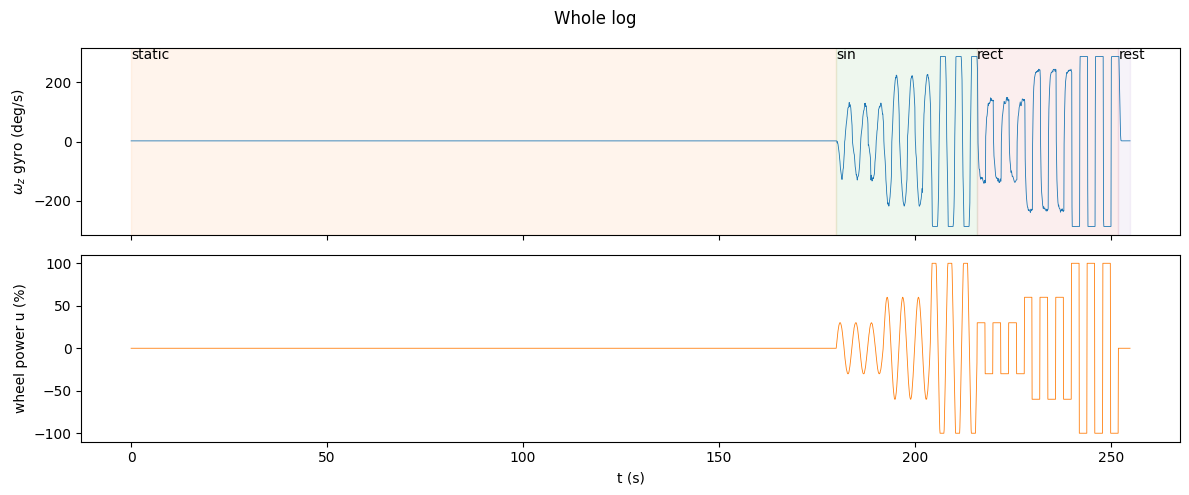

In [2]:
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
ax[0].plot(df.t, df.gz, lw=.6); ax[0].set_ylabel('$\\omega_z$ gyro (deg/s)')
ax[1].plot(df.t, df.u, lw=.6, c='tab:orange'); ax[1].set_ylabel('wheel power u (%)'); ax[1].set_xlabel('t (s)')
for p, g in df.groupby('phase'):
    ax[0].axvspan(g.t.min(), g.t.max(), alpha=.08, color=f'C{p}'); ax[0].text(g.t.min(), ax[0].get_ylim()[1], PH[p], va='top')
fig.suptitle('Whole log'); plt.tight_layout(); plt.show()

## §1 Offset (bias) $b_0$

Mean rate at rest. $b_0(T)$ = mean of the first $T$ seconds: where it stops moving is the calibration time I need.

b0 (first 30 s) = 2.1302 deg/s  +- 0.0034 (standard error)


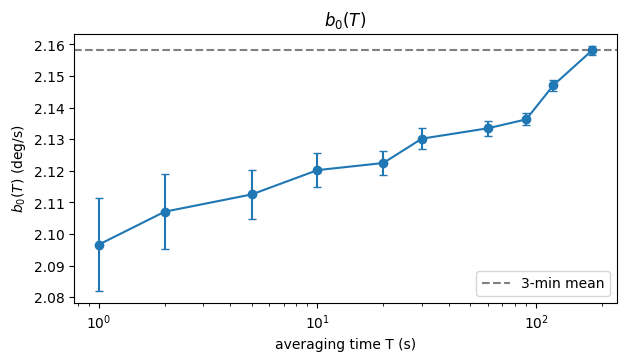

In [3]:
st = df[df.phase == 1]
ts, ws = st.t.values - st.t.values[0], st.gz.values

b0 = ws[ts < 30].mean()
se = ws[ts < 30].std(ddof=1) / np.sqrt((ts < 30).sum())
print(f'b0 (first 30 s) = {b0:.4f} deg/s  +- {se:.4f} (standard error)')

Ts = np.array([1, 2, 5, 10, 20, 30, 60, 90, 120, 180])
b0T = np.array([ws[ts < T].mean() for T in Ts])
seT = np.array([ws[ts < T].std(ddof=1) / np.sqrt((ts < T).sum()) for T in Ts])
plt.figure(figsize=(7, 3.5))
plt.errorbar(Ts, b0T, seT, marker='o', capsize=3); plt.xscale('log')
plt.axhline(ws.mean(), ls='--', c='gray', label='3-min mean')
plt.xlabel('averaging time T (s)'); plt.ylabel('$b_0(T)$ (deg/s)'); plt.legend(); plt.title('$b_0(T)$'); plt.show()

**My calibration method.** The median of the first `T_CAL` seconds after throwing away samples further than
4 robust sigmas (MAD) from it. The median ignores a bump or a spike; `T_CAL` is read off the $b_0(T)$ curve
(the first $T$ whose value is within 0.01 deg/s of the 30-s value — 0.01 deg/s is 0.6° of heading per minute).

In [4]:
def calibrate_gyro(log, T_CAL=10.0, k=4.0):
    '''Offset in deg/s from the first T_CAL seconds of the static phase.'''
    s = log[log.phase == 1]
    w = s.gz.values[(s.t.values - s.t.values[0]) < T_CAL]
    med = np.median(w)
    mad = 1.4826 * np.median(np.abs(w - med)) or 1e-9
    return np.median(w[np.abs(w - med) < k * mad])

# shortest T whose b0(T) is within tol of the 30-s value; tol = 0.01 deg/s = 0.6 deg/min of heading
tol = max(2 * se, 0.01)
T_CAL = next(T for T, b in zip(Ts, b0T) if abs(b - b0) <= tol)
b0_cal = calibrate_gyro(df, T_CAL)
print(f'T_CAL = {T_CAL} s  ->  b0 = {b0_cal:.4f} deg/s')

T_CAL = 10 s  ->  b0 = 2.1305 deg/s


## §2 Bias drift $d$

Mean of each 30-s window of the static log, line fit → slope $d$. Then integrate the rate with the real timestamps
(trapezoid): raw (≈ $b_0 t$, linear) and with $b_0$ removed (what is left after calibration).

d = 0.0241 deg/s per min
uncorrected heading drift = 129.54 deg/min   (check: b0*60 = 127.83)
  after 1 min: raw   128.17 deg   corrected   0.216 deg
  after 2 min: raw   257.71 deg   corrected   2.011 deg
  after 3 min: raw   388.19 deg   corrected   4.968 deg


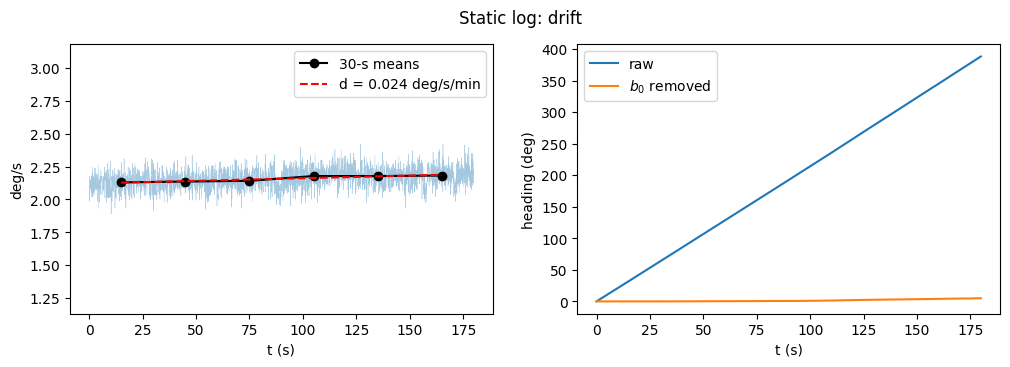

In [5]:
from scipy.integrate import cumulative_trapezoid as ctrap
win = np.arange(0, ts.max() - 29, 30)
wc = win + 15
wm = np.array([ws[(ts >= a) & (ts < a + 30)].mean() for a in win])
d_per_s, _ = np.polyfit(wc, wm, 1)
d = d_per_s * 60                                                   # deg/s per min
th_raw = ctrap(ws, ts, initial=0)
th_cor = ctrap(ws - b0_cal, ts, initial=0)
raw_slope = np.polyfit(ts, th_raw, 1)[0] * 60                      # deg/min
print(f'd = {d:.4f} deg/s per min')
print(f'uncorrected heading drift = {raw_slope:.2f} deg/min   (check: b0*60 = {b0_cal*60:.2f})')
for m in (1, 2, 3):
    i = min(np.searchsorted(ts, 60 * m), len(ts) - 1)
    print(f'  after {m} min: raw {th_raw[i]:8.2f} deg   corrected {th_cor[i]:7.3f} deg')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(ts, ws, lw=.3, alpha=.4); ax[0].plot(wc, wm, 'o-', c='k', label='30-s means')
ax[0].plot(wc, np.polyval([d_per_s, _], wc), 'r--', label=f'd = {d:.3f} deg/s/min')
ax[0].set_ylim(wm.min() - 1, wm.max() + 1); ax[0].set_xlabel('t (s)'); ax[0].set_ylabel('deg/s'); ax[0].legend()
ax[1].plot(ts, th_raw, label='raw'); ax[1].plot(ts, th_cor, label='$b_0$ removed')
ax[1].set_xlabel('t (s)'); ax[1].set_ylabel('heading (deg)'); ax[1].legend(); plt.suptitle('Static log: drift'); plt.show()

## Rotation run: gyro angle vs encoder angle

$\theta_{gyro} = \int(\omega_z - b_0)\,dt$, $\theta_{enc} = \frac{r}{L}(\varphi_R - \varphi_L)$, error $e = \theta_{gyro} - \theta_{enc}$.

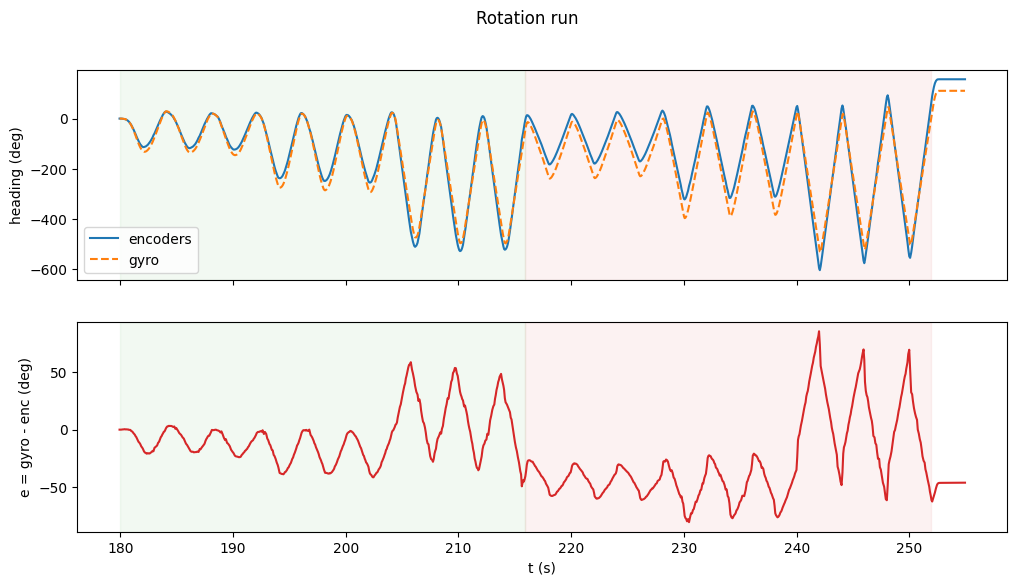

at the end of the run: gyro 110.7 deg, encoders 156.6 deg, e = -45.9 deg, tape = 160


In [6]:
rot = df[df.phase >= 2].copy()
tr = rot.t.values
rot['th_gyro'] = ctrap(rot.gz - b0_cal, tr, initial=0)
rot['th_enc'] -= rot.th_enc.iloc[0]
rot['e'] = rot.th_gyro - rot.th_enc
k = max(1, int(round(0.05 / np.median(np.diff(tr)[np.diff(tr) > 0]))))   # ~50 ms smoothing
rot['w_enc'] = pd.Series(np.gradient(rot.th_enc, tr)).rolling(k, center=True, min_periods=1).mean().values

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(tr, rot.th_enc, label='encoders'); ax[0].plot(tr, rot.th_gyro, '--', label='gyro')
ax[0].set_ylabel('heading (deg)'); ax[0].legend()
ax[1].plot(tr, rot.e, c='tab:red'); ax[1].set_ylabel('e = gyro - enc (deg)'); ax[1].set_xlabel('t (s)')
for a in ax:
    for p in (2, 3):
        g = rot[rot.phase == p]; a.axvspan(g.t.min(), g.t.max(), alpha=.06, color=f'C{p}')
plt.suptitle('Rotation run'); plt.show()

end = rot.iloc[-5:]                # last samples: at the start of 'rest' the robot is still coasting
print(f'at the end of the run: gyro {end.th_gyro.mean():.1f} deg, encoders {end.th_enc.mean():.1f} deg, '
      f'e = {end.e.mean():.1f} deg, tape = {SLIP_DEG}')

## §3 Measurement range $\pm\omega_{max}$

Gyro rate against encoder rate. While the gyro follows, the points lie on the line; saturation is a flat top.
If the robot never reaches the limit, the range is only known to be **larger** than the fastest rate seen
(spin the robot by hand on a chair to find it).

+w_max:   286.7 deg/s  (135 samples at the limit, encoders up to  389.7)  SATURATED
-w_max:  -286.4 deg/s  (136 samples at the limit, encoders up to -371.7)  SATURATED


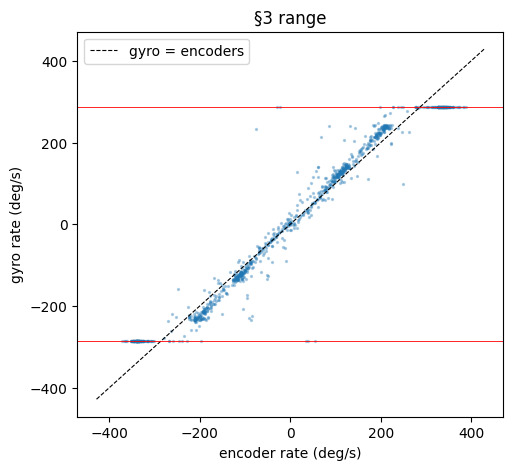

In [7]:
gmax, gmin = rot.gz.max(), rot.gz.min()
near = lambda v: (np.abs(rot.gz - v) < 0.005 * abs(v)).sum()
SAT = {}
for name, v, faster in (('+', gmax, rot.w_enc.max()), ('-', gmin, rot.w_enc.min())):
    sat = SAT[name] = near(v) > 5 and abs(faster) > 1.02 * abs(v)
    print(f'{name}w_max: {v:7.1f} deg/s  ({near(v)} samples at the limit, encoders up to {faster:6.1f})  '
          + ('SATURATED' if sat else 'not reached -> range is larger'))
plt.figure(figsize=(5.5, 5))
plt.scatter(rot.w_enc, rot.gz, s=2, alpha=.3)
lim = 1.1 * max(abs(rot.w_enc).max(), abs(rot.gz).max())
plt.plot([-lim, lim], [-lim, lim], 'k--', lw=.8, label='gyro = encoders')
plt.axhline(gmax, c='r', lw=.6); plt.axhline(gmin, c='r', lw=.6)
plt.xlabel('encoder rate (deg/s)'); plt.ylabel('gyro rate (deg/s)'); plt.legend(); plt.title('§3 range'); plt.show()

## §4 Resolution $\Delta$

Smallest non-zero step between the distinct values the sensor outputs in the static log.

In [8]:
def step(v):
    u = np.unique(v); dv = np.diff(u)
    return dv[dv > 0].min() if len(dv) else np.nan

D_raw = step(st.gz_raw)                                       # counts
if np.ptp(df.gz_raw) > 0:                                     # raw -> mdeg/s factor, from the rotation run
    K = np.polyfit(df.gz_raw[df.phase >= 2], df.gz_cal[df.phase >= 2], 1)[0]
    D_cal = D_raw * K / 1000                                  # one raw count, deg/s
else:                                                         # 2D model: System Call blocks don't run, gz_raw = 0
    K, D_cal = np.nan, step(st.gz_cal) / 1000
print(f'raw -> mdeg/s factor K = {K:.3f};  smallest raw step = {D_raw} count  ->  Delta = {D_cal*1000:.2f} mdeg/s = {D_cal:.5f} deg/s')
print('(gz_cal itself steps by 8 or 9 mdeg/s: K x counts, rounded to whole mdeg/s)')
print('distinct gz_cal values in the static log:', np.unique(st.gz_cal)[:12], '...')

raw -> mdeg/s factor K = 8.756;  smallest raw step = 1 count  ->  Delta = 8.76 mdeg/s = 0.00876 deg/s
(gz_cal itself steps by 8 or 9 mdeg/s: K x counts, rounded to whole mdeg/s)
distinct gz_cal values in the static log: [1890 1916 1925 1933 1942 1951 1960 1968 1977 1986 1995 2003] ...


## §5 Noise $\sigma$

Standard deviation at rest with $b_0$ removed. This σ is the measurement noise **R** of Lab 12 at this sample rate.

sigma = 0.0749 deg/s   robust sigma (MAD) = 0.0771   excess kurtosis = 0.10 (0 = Gaussian)   samples > 4 sigma: 0
sigma >> robust sigma or big kurtosis = spikes (bumps), not Gaussian noise


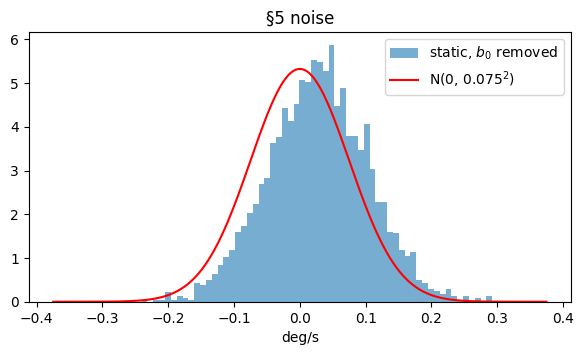

In [9]:
n0 = ws - b0_cal
sigma = n0.std(ddof=1)
kurt = ((n0 - n0.mean())**4).mean() / max(sigma**4, 1e-12) - 3
out = (np.abs(n0) > 4 * sigma).sum() if sigma > 0 else 0
sig_rob = 1.4826 * np.median(np.abs(n0 - np.median(n0)))
print(f'sigma = {sigma:.4f} deg/s   robust sigma (MAD) = {sig_rob:.4f}   excess kurtosis = {kurt:.2f} (0 = Gaussian)'
      f'   samples > 4 sigma: {out}')
print('sigma >> robust sigma or big kurtosis = spikes (bumps), not Gaussian noise')
plt.figure(figsize=(7, 3.5))
plt.hist(n0, bins=60, density=True, alpha=.6, label='static, $b_0$ removed')
if sigma > 0:
    x = np.linspace(-5 * sigma, 5 * sigma, 300)
    plt.plot(x, np.exp(-x**2 / (2 * sigma**2)) / (sigma * np.sqrt(2 * np.pi)), 'r', label=f'N(0, {sigma:.3f}$^2$)')
plt.xlabel('deg/s'); plt.legend(); plt.title('§5 noise'); plt.show()

## §6 Scale factor $s$ and sign

* **Sign:** gyro and encoders must agree (CCW positive). The setup cell checks the correlation of the two rates and flips the gyro if needed (`SIGN`).
* **raw → deg/s:** slope of `gz_cal` against `gz_raw`.
* **s:** each turn (a stretch where the encoder angle moves one way) gives $\Delta\theta_{gyro}/\Delta\theta_{enc} = 1+s$.
  Grouped by direction (CCW/CW) and amplitude. Turns that touched the gyro limit are left out.

$\theta_{enc}$ uses $r/L$ — a 5 % error in $L$ looks exactly like $s = 5\,\%$. The tape mark decides which sensor is right.

sign: raw gyro is CCW positive (flipped in the setup cell if CW); after that corr(gyro, encoder rate) = +0.978
                mean  count
phase A   dir              
rect  30  CCW  11.32      3
          CW   12.85      3
      60  CCW  11.37      3
          CW   11.53      3
      150 CCW -17.08      3
          CW  -17.49      3
sin   30  CCW  12.38      3
          CW   13.66      3
      60  CCW  12.39      3
          CW   11.90      3
      150 CCW  -9.22      3
          CW   -7.61      3



s (unsaturated turns): CCW +11.86 %   CW +12.49 %
same turns with r = 0.042 instead of 0.0375:  CCW -0.12 %   CW +0.43 %


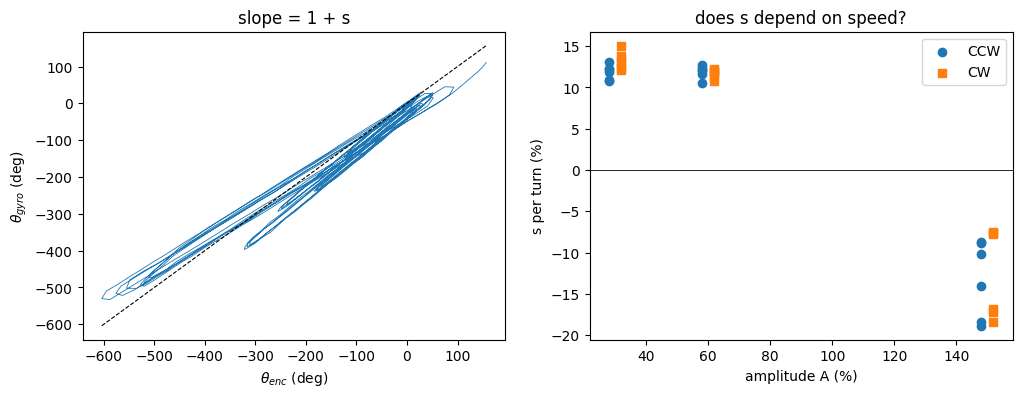

In [10]:
c = np.corrcoef(rot.gz, rot.w_enc)[0, 1]
print(f'sign: raw gyro is {"CCW" if SIGN > 0 else "CW"} positive (flipped in the setup cell if CW);'
      f' after that corr(gyro, encoder rate) = {c:+.3f}')

# one segment per direction change of the encoder angle
sgn_ = np.sign(rot.w_enc.where(rot.w_enc.abs() > 5, 0)).values
seg_id = np.cumsum(np.r_[0, np.abs(np.diff(sgn_)) > 0])
A_of = lambda t: np.where(t < 12, 30, np.where(t < 24, 60, 150))
rows = []
for _, g in rot[sgn_ != 0].groupby(seg_id[sgn_ != 0]):
    den = g.th_enc.iloc[-1] - g.th_enc.iloc[0]
    if abs(den) < 10: continue
    t_in = g.t.iloc[0] - df[df.phase == g.phase.iloc[0]].t.min()
    rows.append(dict(phase=PH[g.phase.iloc[0]], A=int(A_of(t_in)), dir='CCW' if den > 0 else 'CW',
                     d_enc=den, s_pct=100 * ((g.th_gyro.iloc[-1] - g.th_gyro.iloc[0]) / den - 1),
                     sat=bool((SAT['+'] and (np.abs(g.gz - gmax) < .005 * abs(gmax)).any()) or (SAT['-'] and (np.abs(g.gz - gmin) < .005 * abs(gmin)).any()))))
seg = pd.DataFrame(rows)
print(seg.groupby(['phase', 'A', 'dir']).s_pct.agg(['mean', 'count']).round(2))
ok = seg[~seg.sat]
s_ccw, s_cw = ok[ok.dir == 'CCW'].s_pct.mean(), ok[ok.dir == 'CW'].s_pct.mean()
print(f'\ns (unsaturated turns): CCW {s_ccw:+.2f} %   CW {s_cw:+.2f} %')
# s is measured against the encoders, so it includes any error in r/L. The professor's files use two radii:
R_ALT = 0.042
s_alt = [((1 + v / 100) / (R_ALT / R_WHEEL) - 1) * 100 for v in (s_ccw, s_cw)]
print(f'same turns with r = {R_ALT} instead of {R_WHEEL}:  CCW {s_alt[0]:+.2f} %   CW {s_alt[1]:+.2f} %')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(rot.th_enc, rot.th_gyro, lw=.6); ax[0].plot(*[[rot.th_enc.min(), rot.th_enc.max()]] * 2, 'k--', lw=.8)
ax[0].set_xlabel('$\\theta_{enc}$ (deg)'); ax[0].set_ylabel('$\\theta_{gyro}$ (deg)'); ax[0].set_title('slope = 1 + s')
for dname, mk in (('CCW', 'o'), ('CW', 's')):
    q = seg[seg.dir == dname]; ax[1].scatter(q.A + (2 if dname == 'CW' else -2), q.s_pct, marker=mk, label=dname)
ax[1].axhline(0, c='k', lw=.6); ax[1].set_xlabel('amplitude A (%)'); ax[1].set_ylabel('s per turn (%)'); ax[1].legend()
ax[1].set_title('does s depend on speed?'); plt.show()

## Simulated gyro `gyro_sim(omega_true, t)`

The model with my parameters. Input: the encoder rate of the rotation run as $\omega_{true}$. The overlay
should look like the real log: same offset, same noise band, same flat tops.

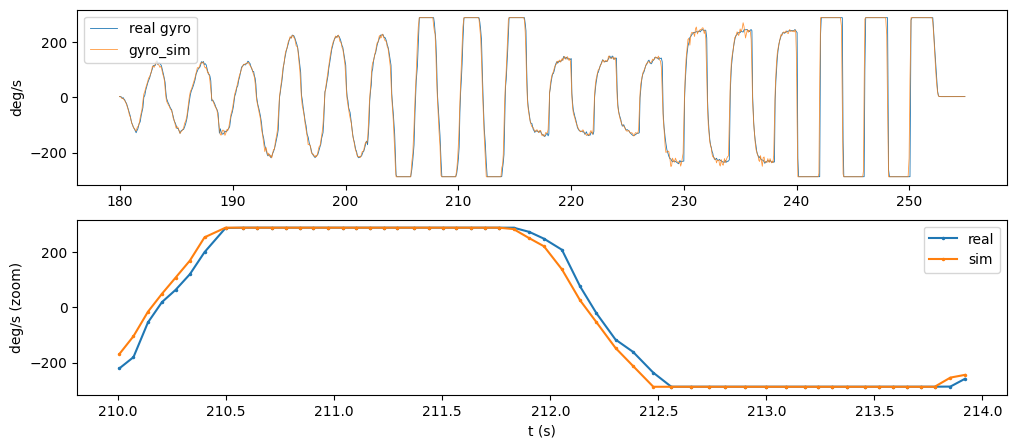

In [11]:
P = dict(b0=b0_cal, d=d / 60, s=np.nanmean([s_ccw, s_cw]) / 100, w_max=max(abs(gmax), abs(gmin)),
         delta=D_cal, sigma=sigma)

def gyro_sim(omega_true, t, p=P, seed=0):
    '''Simulated TRIK gyro: omega_true (deg/s) at times t (s) -> measured rate (deg/s).'''
    rng = np.random.default_rng(seed)
    w = (1 + p['s']) * np.asarray(omega_true) + p['b0'] + p['d'] * np.asarray(t) + rng.normal(0, p['sigma'], len(t))
    w = np.clip(w, -p['w_max'], p['w_max'])
    return p['delta'] * np.round(w / p['delta']) if p['delta'] > 0 else w

sim = gyro_sim(rot.w_enc.values, tr - tr[0])
fig, ax = plt.subplots(2, 1, figsize=(12, 5))
ax[0].plot(tr, rot.gz, lw=.6, label='real gyro'); ax[0].plot(tr, sim, lw=.6, alpha=.8, label='gyro_sim'); ax[0].legend(); ax[0].set_ylabel('deg/s')
z = (tr > tr[0] + 30) & (tr < tr[0] + 34)
ax[1].plot(tr[z], rot.gz[z], '.-', ms=3, label='real'); ax[1].plot(tr[z], sim[z], '.-', ms=3, label='sim'); ax[1].legend()
ax[1].set_xlabel('t (s)'); ax[1].set_ylabel('deg/s (zoom)'); plt.show()

## Parameter table

In [12]:
fmt = lambda v, n=4: 'n/a' if v is None or (isinstance(v, float) and np.isnan(v)) else f'{v:.{n}g}'
table = pd.DataFrame([
    ['Offset (bias)', 'b0', fmt(b0_cal), 'deg/s', f'median of static, T = {T_CAL} s, MAD outliers removed'],
    ['Bias drift', 'd', fmt(d), 'deg/s/min', '30-s window means, line fit'],
    ['Heading drift, uncorrected', '', fmt(raw_slope), 'deg/min', 'slope of integrated raw rate'],
    ['Measurement range', '±w_max', f'+{fmt(gmax)} / {fmt(gmin)}', 'deg/s', 'max |rate| in rotation run (see §3: saturated or not)'],
    ['Resolution', 'Δ', fmt(D_cal), 'deg/s', 'one raw count (smallest gz_raw step) × K'],
    ['Noise std', 'σ', fmt(sigma), 'deg/s', 'static 3 min, b0 removed'],
    ['Raw -> deg/s factor', '', fmt(K / 1000), 'deg/s per count', 'slope gz_cal vs gz_raw'],
    ['Scale-factor error CCW / CW', 's', f'{s_ccw:+.2f} / {s_cw:+.2f}', '%', f'Δθ_gyro/Δθ_enc − 1 per unsaturated turn, r = {R_WHEEL}'],
    ['  same, encoders with r = 0.042', 's', f'{s_alt[0]:+.2f} / {s_alt[1]:+.2f}', '%', 'the +12 % above is the wheel radius'],
    ['Positive rotation direction', '', 'CCW' if SIGN > 0 else 'CW', '—', 'sign of corr(raw gyro, encoder rate)'],
], columns=['Parameter', 'Symbol', 'Value', 'Unit', 'Method'])
table

,Parameter,Symbol,Value,Unit,Method
0,Offset (bias),b0,2.13,deg/s,"median of static, T = 10 s, MAD outliers removed"
1,Bias drift,d,0.0241,deg/s/min,"30-s window means, line fit"
2,"Heading drift, uncorrected",,129.5,deg/min,slope of integrated raw rate
3,Measurement range,±w_max,+286.7 / -286.4,deg/s,max |rate| in rotation run (see §3: saturated ...
4,Resolution,Δ,0.008756,deg/s,one raw count (smallest gz_raw step) × K
5,Noise std,σ,0.07495,deg/s,"static 3 min, b0 removed"
6,Raw -> deg/s factor,,0.008756,deg/s per count,slope gz_cal vs gz_raw
7,Scale-factor error CCW / CW,s,+11.86 / +12.49,%,"Δθ_gyro/Δθ_enc − 1 per unsaturated turn, r = 0..."
8,"same, encoders with r = 0.042",s,-0.12 / +0.43,%,the +12 % above is the wheel radius
9,Positive rotation direction,,CCW,—,"sign of corr(raw gyro, encoder rate)"


## Which error dominates when?

Heading error each source would cause on its own (deg). Gain error assumes one full turn (360°) in that time and uses
$s$ measured against encoders with $r$ = 0.042 m (the +12 % against $r$ = 0.0375 m is the wheel radius, not the gyro — §6).
Noise grows as $\sigma\sqrt{\Delta t\, t}$ (random walk of the integral). Saturation is not in the table: it only
happens above ±ω_max, and then it loses a lot (8–17 % of each clipped turn, §6).

In [13]:
dt_s = np.median(np.diff(ts)[np.diff(ts) > 0])
se_cal = sigma / np.sqrt(T_CAL / dt_s)                 # standard error of a T_CAL-second calibration
budget = pd.DataFrame({T: {'bias, not calibrated  |b0| t': abs(b0_cal) * T,
                           'bias left after calibration  SE t': se_cal * T,
                           'drift  |d| t^2 / 2': abs(d / 60) * T**2 / 2,
                           'noise  sigma sqrt(dt t)': sigma * np.sqrt(dt_s * T),
                           'gyro gain error  |s| 360': abs(np.nanmean(s_alt)) / 100 * 360}
                       for T in (10, 60, 180)}).round(3)
budget.columns = ['10 s', '1 min', '3 min']
budget

,10 s,1 min,3 min
"bias, not calibrated |b0| t",21.305,127.830,383.490
bias left after calibration SE t,0.060,0.363,1.088
drift |d| t^2 / 2,0.020,0.723,6.507
noise sigma sqrt(dt t),0.060,0.148,0.256
gyro gain error |s| 360,0.562,0.562,0.562


## Short analysis (≤ 1 page)

Real run 2026-11-19, robot 192.168.50.229, loop period 65 ms, Option A (sin + square, A = 30/60/150 %).

**Which error dominates.** The offset, by far: $b_0$ = 2.13 °/s turns into 21° after 10 s, 128° after 1 min and 383° after 3 min
if it is not removed. After calibration the order changes with time: at 10 s every source is below 0.1°; at 1 min drift (0.7°)
and calibration error (0.4°) are similar; at 3 min drift wins (6.5°) over calibration error (1.1°) and noise (0.26°).
On a fast-turning robot, saturation beats all of them: 46° lost in 75 s of spinning.

**My calibration.** `calibrate_gyro()` takes the median of the first 10 s of the static log after cutting samples more
than 4 robust sigmas (MAD) from it, so a bump against the table cannot move it. 10 s because the $b_0(T)$ curve stays
within 0.01 °/s of the 30-s value from there on (standard error 0.006 °/s, i.e. 1.1° in 3 min). Standing still for 3 min
after calibration, the heading is off by 5.0° — nearly all of it the bias drift $d$ = +0.024 °/s per min, which a start-up
calibration cannot remove.

**Where $e(t)$ grows.** Not at rest. At A = 30 and 60 % it swings by a fixed ≈ 12 % of every turn and comes back: a scale
factor, the same for CCW and CW and for both speeds. At A = 150 % it jumps by up to 50° per turn: the robot spins at up to
390 °/s and the gyro is clipped at ±287 °/s (32767 counts × 8.75 mdeg/s), so those turns read 8–17 % short.

**Gyro or encoders?** The +12 % is exactly 4.2/3.75 = 1.12, the ratio of the two wheel radii in the professor's files.
With r = 4.2 cm, gyro and encoders agree within −0.1 / +0.4 % on every clean turn, so the gyro's factory gain is right and
the encoder radius was wrong. On fast turns the gyro is the worse sensor (clipped: 111° at the end, vs ≈ 160° by eye and
157° / 175° from the encoders with r = 3.75 / 4.2 cm). The end angle was judged by eye, not with a protractor, so it cannot
separate the two radii; the r = 4.2 cm encoders being ~15° above it fits wheel slip in the hard reversals.